# Corpus de hojas: aprendizaje no supervisado y supervisado

---

## Descripción de la base de datos

El corpus de hojas fue construido por el equipo durante el curso. Las hojas fueron recolectadas a mano por Juan Pablo Martha, integrante del equipo, a inicios de octubre. Se incluyeron hojas de tres tipos de árbol: **Limón**, **Ocozote** y **Fresno**.

Cada hoja se fotografió junto a una regla, que sirvió como escala de referencia. Las medidas de la mayoría de las hojas se obtuvieron a partir de estas fotografías con ayuda de herramientas de inteligencia artificial (Gemini y ChatGPT); unas pocas se midieron directamente con la regla. El alto se midió desde el inicio de la hoja, sin contar el pecíolo.

La etiqueta de cada hoja corresponde al árbol del que fue recolectada. Cada hoja se representa con dos características numéricas:

- **Alto (cm):** longitud de la hoja, sin contar el pecíolo.
- **Ancho (cm):** ancho de la hoja.

La columna `ID hoja` es únicamente un identificador, por lo que no se utiliza como característica.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
datos = pd.read_csv("../data/hojasRazonamiento.csv", encoding="utf-8")

caracteristicas = ["Alto (cm)", "Ancho (cm)"]
columna_clase = "Árbol"

# Orden fijo de las clases: define la codificación 0, 1 y 2
# (este orden afecta al MAE de los modelos supervisados)
CLASES = ["Limón", "Fresno", "Ocozote"]

X = datos[caracteristicas].to_numpy()
y = datos[columna_clase].map({clase: i for i, clase in enumerate(CLASES)}).to_numpy()

# Verificar que se cargó el corpus de hojas completo
if X.shape != (150, 2):
    raise ValueError(
        f"Se esperaba X con forma (150, 2) y se obtuvo {X.shape}. "
        "Verifica que se cargó data/hojasRazonamiento.csv."
    )

if np.isnan(y.astype(float)).any() or datos.isna().any().any():
    raise ValueError("Existen etiquetas desconocidas o valores faltantes.")

# Colores fijos por clase, utilizados en todas las figuras
COLORES_CLASE = {
    "Limón": "forestgreen",
    "Fresno": "darkorange",
    "Ocozote": "royalblue"
}

# Colores para los clústeres (distintos a los de las clases)
COLORES_CLUSTER = [
    "mediumpurple", "teal", "goldenrod",
    "hotpink", "sienna", "slategray"
]

print("Tamaño de X:", X.shape)
print("Tamaño de y:", y.shape)
print("Clases (código):", {i: clase for i, clase in enumerate(CLASES)})
print("Características:", caracteristicas)
print("Valores faltantes:", datos.isna().sum().sum())

Tamaño de X: (150, 2)
Tamaño de y: (150,)
Clases (código): {0: 'Limón', 1: 'Fresno', 2: 'Ocozote'}
Características: ['Alto (cm)', 'Ancho (cm)']
Valores faltantes: 0


In [3]:
datos.head()

,ID hoja,Árbol,Alto (cm),Ancho (cm)
0,1,Limón,4.7,2.5
1,2,Limón,6.8,3.7
2,3,Limón,5.4,2.7
3,4,Limón,7.0,3.6
4,5,Limón,4.7,2.3


In [4]:
decimales = (datos[caracteristicas] * 10 % 1).abs().round(6)
pares_repetidos = datos.duplicated(subset=caracteristicas).sum()

print("Medidas con más de un decimal:", int((decimales > 0).sum().sum()))
print("Hojas con un par (Alto, Ancho) idéntico a otra hoja:", pares_repetidos)
print()
print("Rango de ID por clase:")
print(datos.groupby(columna_clase)["ID hoja"].agg(["min", "max"]).loc[CLASES])

Medidas con más de un decimal: 0
Hojas con un par (Alto, Ancho) idéntico a otra hoja: 10

Rango de ID por clase:
         min  max
Árbol            
Limón      1   50
Fresno   101  150
Ocozote   51  100


## Distribución por clase

In [5]:
distribucion = (
    datos[columna_clase]
    .value_counts()
    .reindex(CLASES)
    .rename("Número de hojas")
    .to_frame()
)

distribucion["Porcentaje (%)"] = (
    distribucion["Número de hojas"] / len(datos) * 100
).round(2)

print("Número total de hojas:", len(datos))
print("Número de clases:", len(CLASES))
distribucion

Número total de hojas: 150
Número de clases: 3


,Número de hojas,Porcentaje (%)
Árbol,,
Limón,50,33.33
Fresno,50,33.33
Ocozote,50,33.33


La base contiene **150 hojas** distribuidas en **3 clases** con **50 hojas cada una** (33.33 %). Al ser una base balanceada, ninguna clase domina el entrenamiento y las métricas con promedio macro dan el mismo peso a las tres clases.

## Estadísticas descriptivas por clase

Para cada clase se calculan la media, la desviación estándar, el mínimo y el máximo de las dos características.

In [6]:
estadisticas = (
    datos
    .groupby(columna_clase)[caracteristicas]
    .agg(["mean", "std", "min", "max"])
    .loc[CLASES]
    .round(2)
)

estadisticas = estadisticas.rename(
    columns={
        "mean": "Media",
        "std": "Desv. estándar",
        "min": "Mínimo",
        "max": "Máximo"
    },
    level=1
)

estadisticas

Alto (cm)                              Ancho (cm)                 \
            Media Desv. estándar Mínimo Máximo      Media Desv. estándar   
Árbol                                                                      
Limón        6.02           0.89    4.3    7.6       3.05           0.45   
Fresno      10.94           1.85    7.6   14.3       3.45           0.73   
Ocozote     12.81           2.75    8.0   17.7      12.10           1.97   

                       
        Mínimo Máximo  
Árbol                  
Limón      2.2    3.9  
Fresno     2.1    4.8  
Ocozote    8.0   15.9

In [7]:
estadisticas_globales = (
    datos[caracteristicas]
    .agg(["mean", "std", "min", "max"])
    .rename(index={
        "mean": "Media",
        "std": "Desv. estándar",
        "min": "Mínimo",
        "max": "Máximo"
    })
    .round(2)
)

estadisticas_globales

,Alto (cm),Ancho (cm)
Media,9.93,6.20
Desv. estándar,3.48,4.37
Mínimo,4.30,2.10
Máximo,17.70,15.90


## Gráficas exploratorias

Todas las gráficas se presentan en el espacio original de las dos características, medidas en centímetros. No se aplica PCA a esta base.

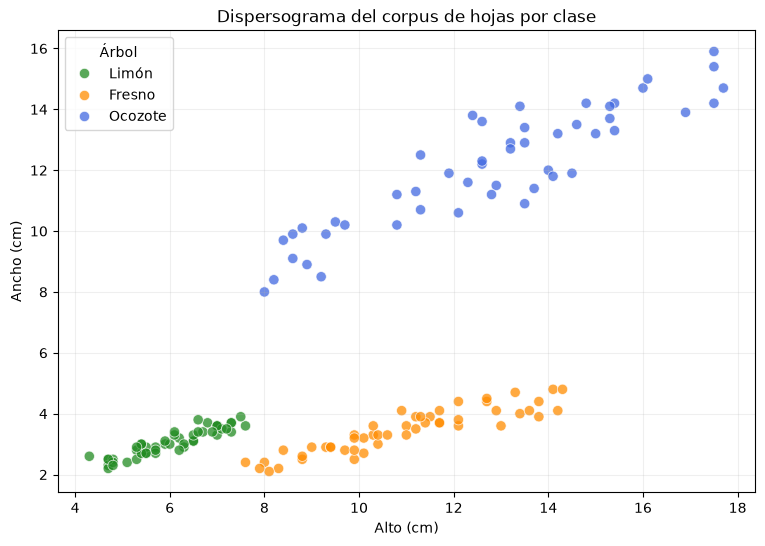

In [8]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Alto (cm)",
    y="Ancho (cm)",
    hue=columna_clase,
    hue_order=CLASES,
    palette=COLORES_CLASE,
    alpha=0.75,
    s=55
)

plt.title("Dispersograma del corpus de hojas por clase")
plt.xlabel("Alto (cm)")
plt.ylabel("Ancho (cm)")
plt.legend(title="Árbol")
plt.grid(alpha=0.2)
plt.show()

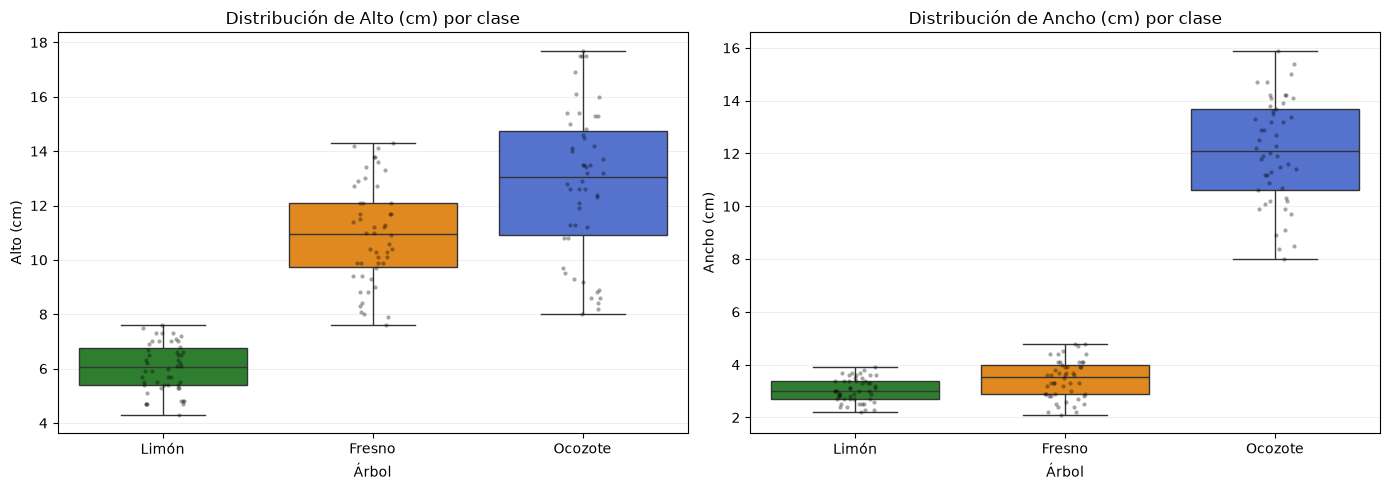

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, caracteristica in zip(axes, caracteristicas):
    sns.boxplot(
        data=datos,
        x=columna_clase,
        y=caracteristica,
        hue=columna_clase,
        order=CLASES,
        hue_order=CLASES,
        palette=COLORES_CLASE,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=datos,
        x=columna_clase,
        y=caracteristica,
        order=CLASES,
        color="black",
        alpha=0.35,
        size=3,
        ax=ax
    )

    ax.set_title(f"Distribución de {caracteristica} por clase")
    ax.set_xlabel("Árbol")
    ax.set_ylabel(caracteristica)
    ax.grid(alpha=0.2, axis="y")

plt.tight_layout()
plt.show()

In [10]:
# Traslape de rangos entre clases para cada característica
for caracteristica in caracteristicas:
    print(f"{caracteristica}:")

    for i, clase_a in enumerate(CLASES):
        for clase_b in CLASES[i + 1:]:
            a = datos.loc[datos[columna_clase] == clase_a, caracteristica]
            b = datos.loc[datos[columna_clase] == clase_b, caracteristica]

            inicio = max(a.min(), b.min())
            fin = min(a.max(), b.max())

            if inicio <= fin:
                en_traslape = (
                    a.between(inicio, fin).sum()
                    + b.between(inicio, fin).sum()
                )
                print(
                    f"  {clase_a} y {clase_b}: traslape de {inicio:.1f} a {fin:.1f} cm "
                    f"({en_traslape} de {len(a) + len(b)} hojas dentro del traslape)"
                )
            else:
                print(f"  {clase_a} y {clase_b}: sin traslape")
    print()

Alto (cm):
  Limón y Fresno: traslape de 7.6 a 7.6 cm (2 de 100 hojas dentro del traslape)
  Limón y Ocozote: sin traslape
  Fresno y Ocozote: traslape de 8.0 a 14.3 cm (83 de 100 hojas dentro del traslape)

Ancho (cm):
  Limón y Fresno: traslape de 2.2 a 3.9 cm (86 de 100 hojas dentro del traslape)
  Limón y Ocozote: sin traslape
  Fresno y Ocozote: sin traslape



In [11]:
# Relación entre alto y ancho dentro de cada clase
relacion = pd.DataFrame({
    "Correlación Alto-Ancho": datos.groupby(columna_clase).apply(
        lambda g: g["Alto (cm)"].corr(g["Ancho (cm)"]),
        include_groups=False
    ),
    "Proporción Alto/Ancho (media)": (
        datos["Alto (cm)"] / datos["Ancho (cm)"]
    ).groupby(datos[columna_clase]).mean()
}).loc[CLASES].round(2)

relacion

,Correlación Alto-Ancho,Proporción Alto/Ancho (media)
Árbol,,
Limón,0.92,1.98
Fresno,0.91,3.21
Ocozote,0.91,1.05


### Interpretación del análisis exploratorio

La gráfica de dispersión muestra que **Ocozote** se separa claramente de las otras dos clases por su ancho: sus hojas miden entre 8.0 y 15.9 cm de ancho, mientras que ninguna hoja de Limón o Fresno supera los 4.8 cm. No existe traslape en el ancho entre Ocozote y las demás clases.

**Limón** y **Fresno** se traslapan casi por completo en el ancho: 86 de sus 100 hojas se encuentran dentro del intervalo común de 2.2 a 3.9 cm. Su diferencia principal está en el alto: las hojas de Limón miden entre 4.3 y 7.6 cm y las de Fresno entre 7.6 y 14.3 cm, por lo que solamente coinciden en el valor de 7.6 cm (2 hojas). En consecuencia, la frontera entre ambas clases depende sobre todo del alto y se ubica alrededor de los 7.6 cm, donde ambas clases quedan muy próximas.

En el alto, Fresno y Ocozote sí presentan un traslape amplio (de 8.0 a 14.3 cm, con 83 de 100 hojas dentro del intervalo), pero esto no afecta su separación, porque el ancho las distingue por completo.

Ocozote es la clase con mayor dispersión en ambas variables (desviación estándar de 2.75 cm en el alto y 1.97 cm en el ancho), mientras que Limón es la más compacta (0.89 y 0.45 cm). Dentro de cada clase, el alto y el ancho están positivamente correlacionados: las hojas más largas también tienden a ser más anchas, con correlaciones de 0.92 en Limón, 0.91 en Fresno y 0.91 en Ocozote. La proporción alto/ancho promedio es de 1.05 en Ocozote (hojas casi tan anchas como largas), 1.98 en Limón y 3.21 en Fresno (hojas alargadas).

Las dos variables tienen escalas diferentes (desviación estándar global de 3.48 cm en el alto y 4.37 cm en el ancho), por lo que los métodos basados en distancias se aplicarán sobre las variables estandarizadas.

Las medidas se registraron con un decimal y 10 hojas comparten exactamente el mismo par (alto, ancho) con otra hoja. Estos valores repetidos se conservan, ya que corresponden a hojas distintas y son esperables con una resolución de 0.1 cm. Finalmente, los identificadores están ordenados por clase (Limón del 1 al 50, Ocozote del 51 al 100 y Fresno del 101 al 150), por lo que las particiones de validación cruzada deberán barajar los datos.

---

# Modelo 1: Clustering jerárquico

El modelo se entrenará utilizando las 2 características del corpus de hojas (alto y ancho) **estandarizadas**. Ambas variables se miden en centímetros, pero tienen rangos y dispersiones distintas, por lo que sin estandarizar la variable con mayor dispersión dominaría el cálculo de distancias.

Se probarán diferentes números de clústeres (de 2 a 6), métodos de enlace y métricas de distancia. La mejor configuración se seleccionará mediante el coeficiente de silueta.

Las etiquetas reales no se utilizarán durante el entrenamiento; solamente servirán posteriormente para interpretar los grupos obtenidos.

---

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Datos originales:", X.shape)
print("Datos estandarizados:", X_scaled.shape)
print("Media después de estandarizar:", X_scaled.mean(axis=0).round(6))
print("Desviación estándar después de estandarizar:", X_scaled.std(axis=0).round(6))

Datos originales: (150, 2)
Datos estandarizados: (150, 2)
Media después de estandarizar: [0. 0.]
Desviación estándar después de estandarizar: [1. 1.]


## Búsqueda de la configuración

Para cada configuración se calculan dos coeficientes de silueta:

- **Silueta euclidiana:** se calcula con la distancia euclidiana sobre las variables estandarizadas para todas las configuraciones. Es el criterio de selección, porque permite comparar configuraciones con métricas distintas en una misma escala y también comparar el resultado con K-means.
- **Silueta con la métrica propia:** se calcula con la misma métrica utilizada por el enlace. Se reporta como referencia, pero no se usa para seleccionar, ya que los valores obtenidos con distancias diferentes no son comparables entre sí.

También se registra el tamaño del clúster más pequeño, para detectar configuraciones que solamente aíslan unas pocas hojas extremas.

**Diferencia con el notebook de cáncer de mama:** en cáncer de mama la silueta de cada configuración se calculó con su propia métrica de distancia, y la configuración seleccionada utilizó distancia coseno. En este notebook se ajustó el procedimiento: todas las configuraciones se comparan con la silueta euclidiana sobre las variables estandarizadas, ya que siluetas calculadas con métricas distintas no están en la misma escala. Por ello, las siluetas del clustering jerárquico de ambas bases no son directamente comparables.

In [14]:
resultados_jerarquico = []

configuraciones = [
    ("ward", "euclidean"),
    ("complete", "euclidean"),
    ("complete", "manhattan"),
    ("complete", "cosine"),
    ("average", "euclidean"),
    ("average", "manhattan"),
    ("average", "cosine"),
    ("single", "euclidean"),
    ("single", "manhattan"),
    ("single", "cosine")
]

for linkage_method, distance_metric in configuraciones:
    for n_clusters in range(2, 7):

        modelo = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=linkage_method,
            metric=distance_metric
        )

        etiquetas_cluster = modelo.fit_predict(X_scaled)
        tamanos = np.bincount(etiquetas_cluster)

        resultados_jerarquico.append({
            "linkage": linkage_method,
            "metrica": distance_metric,
            "n_clusters": n_clusters,
            "silueta_euclidiana": silhouette_score(
                X_scaled,
                etiquetas_cluster,
                metric="euclidean"
            ),
            "silueta_metrica_propia": silhouette_score(
                X_scaled,
                etiquetas_cluster,
                metric=distance_metric
            ),
            "cluster_mas_pequeno": tamanos.min(),
            "tamanos": sorted(tamanos.tolist(), reverse=True)
        })

resultados_df = pd.DataFrame(resultados_jerarquico)

resultados_df = resultados_df.sort_values(
    by="silueta_euclidiana",
    ascending=False
).reset_index(drop=True)

resultados_df.head(10)

,linkage,metrica,n_clusters,silueta_euclidiana,silueta_metrica_propia,cluster_mas_pequeno,tamanos
0,ward,euclidean,4,0.614365,0.614365,11,"[59, 41, 39, 11]"
1,complete,euclidean,5,0.609669,0.609669,11,"[59, 41, 24, 15, 11]"
2,complete,manhattan,5,0.600555,0.589518,11,"[62, 38, 24, 15, 11]"
3,ward,euclidean,2,0.596540,0.596540,39,"[111, 39]"
4,average,manhattan,2,0.596540,0.627596,39,"[111, 39]"
5,average,euclidean,2,0.596540,0.596540,39,"[111, 39]"
6,ward,euclidean,5,0.593362,0.593362,7,"[59, 41, 32, 11, 7]"
7,average,euclidean,4,0.582661,0.582661,11,"[50, 50, 39, 11]"
8,complete,cosine,2,0.580049,0.722074,50,"[100, 50]"
9,complete,manhattan,2,0.580049,0.615633,50,"[100, 50]"


In [15]:
# Mejor configuración para cada número de clústeres
mejor_por_k_jerarquico = (
    resultados_df
    .loc[resultados_df.groupby("n_clusters")["silueta_euclidiana"].idxmax()]
    .reset_index(drop=True)
)

mejor_por_k_jerarquico

,linkage,metrica,n_clusters,silueta_euclidiana,silueta_metrica_propia,cluster_mas_pequeno,tamanos
0,ward,euclidean,2,0.596540,0.596540,39,"[111, 39]"
1,ward,euclidean,3,0.570427,0.570427,39,"[59, 52, 39]"
2,ward,euclidean,4,0.614365,0.614365,11,"[59, 41, 39, 11]"
3,complete,euclidean,5,0.609669,0.609669,11,"[59, 41, 24, 15, 11]"
4,complete,euclidean,6,0.576381,0.576381,11,"[59, 29, 24, 15, 12, 11]"


In [16]:
# Composición de las mejores configuraciones con 2 y 3 clústeres (solo para interpretar)
for _, fila in mejor_por_k_jerarquico[
    mejor_por_k_jerarquico["n_clusters"].isin([2, 3])
].iterrows():
    etiquetas_k = AgglomerativeClustering(
        n_clusters=int(fila["n_clusters"]),
        linkage=fila["linkage"],
        metric=fila["metrica"]
    ).fit_predict(X_scaled)

    print(
        f"{fila['linkage']} + {fila['metrica']}, k = {fila['n_clusters']} "
        f"(silueta = {fila['silueta_euclidiana']:.4f}):"
    )
    display(pd.crosstab(
        etiquetas_k,
        np.array(CLASES)[y],
        rownames=["Cluster"],
        colnames=["Árbol real"]
    )[CLASES])

ward + euclidean, k = 2 (silueta = 0.5965):


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,50,50,11
1,0,0,39


ward + euclidean, k = 3 (silueta = 0.5704):


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,41,11
1,0,0,39
2,50,9,0


In [17]:
# Configuraciones con mayor silueta usando su propia métrica (solo como referencia)
resultados_df.sort_values(
    by="silueta_metrica_propia",
    ascending=False
).head(5)

,linkage,metrica,n_clusters,silueta_euclidiana,silueta_metrica_propia,cluster_mas_pequeno,tamanos
19,average,cosine,5,0.565412,0.860237,11,"[50, 39, 26, 24, 11]"
33,average,cosine,6,0.532439,0.850700,2,"[50, 39, 26, 24, 9, 2]"
16,complete,cosine,4,0.572255,0.840791,11,"[69, 39, 31, 11]"
32,complete,cosine,5,0.539154,0.837893,11,"[50, 39, 31, 19, 11]"
29,complete,cosine,6,0.544616,0.837328,11,"[50, 39, 19, 18, 13, 11]"


In [18]:
# Se descartan configuraciones cuyo clúster más pequeño tenga menos del 5 % de las hojas
tamano_minimo = int(np.ceil(0.05 * len(X_scaled)))

candidatas = resultados_df[
    resultados_df["cluster_mas_pequeno"] >= tamano_minimo
]

mejor_config_jerarquico = candidatas.iloc[0]

print("Configuraciones evaluadas:", len(resultados_df))
print("Tamaño mínimo aceptado por clúster:", tamano_minimo)
print("Configuraciones descartadas:", len(resultados_df) - len(candidatas))
print()
print("Configuración seleccionada:")
print(mejor_config_jerarquico)

Configuraciones evaluadas: 50
Tamaño mínimo aceptado por clúster: 8
Configuraciones descartadas: 14

Configuración seleccionada:
linkage                               ward
metrica                          euclidean
n_clusters                               4
silueta_euclidiana                0.614365
silueta_metrica_propia            0.614365
cluster_mas_pequeno                     11
tamanos                   [59, 41, 39, 11]
Name: 0, dtype: object


## Selección de la mejor configuración

Se evaluaron 50 configuraciones, resultado de combinar 10 pares de enlace y métrica con 2 a 6 clústeres. Se descartaron 14 configuraciones porque formaban algún clúster con menos de 8 hojas (5 % del corpus), es decir, solo aislaban unas pocas hojas extremas.

La configuración seleccionada utiliza enlace **ward**, distancia **euclidiana** y **4 clústeres**. Obtuvo una silueta de **0.6144** y formó grupos de **59, 41, 39 y 11 hojas**.

Las configuraciones con distancia coseno obtuvieron las siluetas más altas cuando se evaluaron con su propia métrica. La mejor, con enlace average y 5 clústeres, llegó a 0.8602, pero con la silueta euclidiana baja a 0.5654. Con solo dos variables estandarizadas, la distancia coseno compara la dirección de cada hoja respecto a la media del corpus e ignora qué tan lejos está de ella. Por eso divide el plano en sectores angulares y su silueta no es comparable con la de las demás métricas.

La silueta **no favorece 3 clústeres**, aunque el corpus contiene tres árboles. La mejor configuración con k = 3 (ward) obtuvo 0.5704, menos que k = 4 (0.6144) y que k = 2 (0.5965):

- Con **k = 2**, el modelo separa 39 hojas de Ocozote y deja en el otro grupo todas las hojas de Limón y Fresno junto con 11 de Ocozote.
- Con **k = 3**, Limón queda en un grupo con 9 hojas de Fresno, y las 11 hojas de Ocozote se unen a las 41 hojas restantes de Fresno.

Por lo tanto, ninguna de estas configuraciones recupera las tres clases. Se conserva la configuración de 4 clústeres indicada por la silueta, sin forzar k = 3.

In [19]:
mejor_modelo_jerarquico = AgglomerativeClustering(
    n_clusters=int(mejor_config_jerarquico["n_clusters"]),
    linkage=mejor_config_jerarquico["linkage"],
    metric=mejor_config_jerarquico["metrica"],
    compute_distances=True
)

clusters_jerarquico = mejor_modelo_jerarquico.fit_predict(X_scaled)
k_jerarquico = mejor_modelo_jerarquico.n_clusters_

valores, cantidades = np.unique(
    clusters_jerarquico,
    return_counts=True
)

print("Clústeres:", valores)
print("Cantidad de hojas por clúster:", cantidades)

Clústeres: [0 1 2 3]
Cantidad de hojas por clúster: [39 41 59 11]


## Dendrograma del clustering jerárquico

El dendrograma representa cómo las hojas se fusionan progresivamente para formar los clústeres. Se utiliza la configuración final. La línea horizontal representa el corte del árbol que produce el número de clústeres seleccionado.

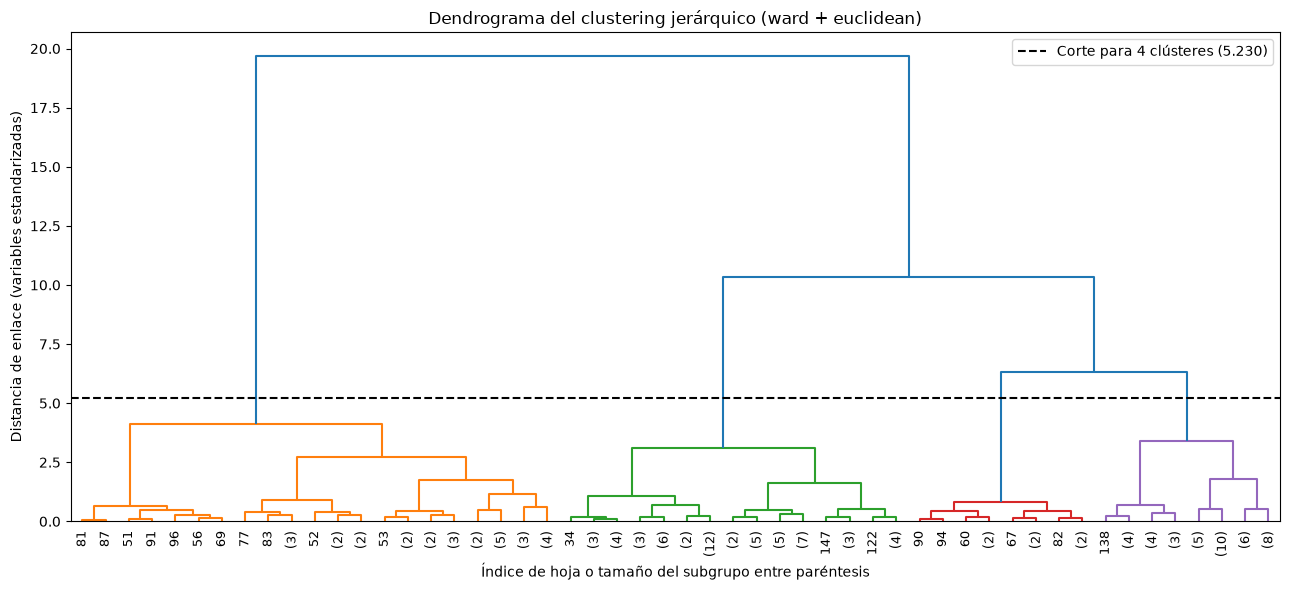

Distancias de las últimas 5 fusiones: [ 3.398  4.128  6.333 10.341 19.702]


In [20]:
from scipy.cluster.hierarchy import dendrogram

def matriz_para_dendrograma(modelo):
    n_muestras = len(modelo.labels_)
    tamanos = np.zeros(len(modelo.children_), dtype=int)

    for i, hijos in enumerate(modelo.children_):
        for hijo in hijos:
            if hijo < n_muestras:
                tamanos[i] += 1
            else:
                tamanos[i] += tamanos[hijo - n_muestras]

    matriz = np.column_stack([
        modelo.children_,
        modelo.distances_,
        tamanos
    ]).astype(float)

    return matriz


matriz_jerarquica = matriz_para_dendrograma(
    mejor_modelo_jerarquico
)

# El corte se ubica entre las dos últimas fusiones que separan k clústeres
corte_jerarquico = matriz_jerarquica[
    [-k_jerarquico, -(k_jerarquico - 1)], 2
].mean()

fig, ax = plt.subplots(figsize=(13, 6))

dendrogram(
    matriz_jerarquica,
    truncate_mode="level",
    p=5,
    leaf_font_size=9,
    color_threshold=corte_jerarquico,
    ax=ax
)

ax.axhline(
    y=corte_jerarquico,
    color="black",
    linestyle="--",
    label=f"Corte para {k_jerarquico} clústeres ({corte_jerarquico:.3f})"
)

ax.set_title(
    "Dendrograma del clustering jerárquico "
    f"({mejor_config_jerarquico['linkage']} + {mejor_config_jerarquico['metrica']})"
)

ax.set_xlabel(
    "Índice de hoja o tamaño del subgrupo entre paréntesis"
)

ax.set_ylabel("Distancia de enlace (variables estandarizadas)")
ax.legend()

plt.tight_layout()
plt.show()

print("Distancias de las últimas 5 fusiones:", matriz_jerarquica[-5:, 2].round(3))

### Interpretación del dendrograma

El dendrograma representa el proceso de agrupamiento de las hojas mediante enlace **ward** y distancia **euclidiana** sobre las variables estandarizadas. Al realizar el corte en una distancia de **5.230**, el árbol queda dividido en cuatro ramas, correspondientes a los cuatro clústeres seleccionados.

Las últimas cinco fusiones ocurren a distancias de 3.398, 4.128, 6.333, 10.341 y 19.702. El corte se ubica entre 4.128 y 6.333; la fusión a 6.333 reduciría los grupos a tres. El salto más grande ocurre en la última fusión (de 10.341 a 19.702), que separa un grupo de 39 hojas del resto. Este salto corresponde a la división en dos grupos, pero la silueta favorece la división en cuatro, porque esos grupos son más compactos.

La gráfica se presenta de forma truncada para facilitar su lectura; los valores entre paréntesis indican la cantidad de hojas contenidas en cada subgrupo.

## Visualización de los clústeres en el plano Alto × Ancho

El modelo fue ajustado con las variables estandarizadas, pero los clústeres se grafican en el **espacio original de las dos características, en centímetros**. Como la estandarización solo cambia la escala de cada eje, la forma de los grupos se conserva. No se utiliza PCA.

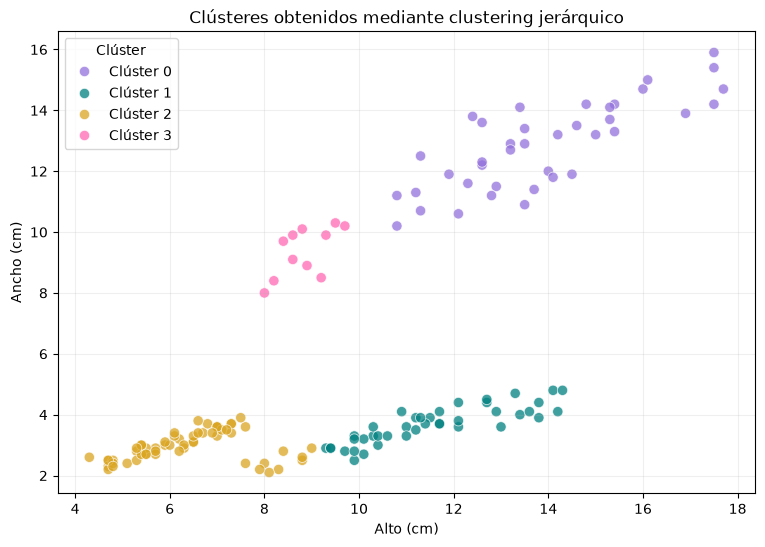

Alto (cm)             Ancho (cm)            
               mean   min   max       mean   min   max
Clúster 0     13.93  10.8  17.7      12.87  10.2  15.9
Clúster 1     11.52   9.3  14.3       3.67   2.5   4.8
Clúster 2      6.37   4.3   9.0       2.96   2.1   3.9
Clúster 3      8.84   8.0   9.7       9.36   8.0  10.3

In [21]:
nombres_cluster_jerarquico = np.array(
    [f"Clúster {c}" for c in clusters_jerarquico]
)

orden_cluster_jerarquico = [f"Clúster {c}" for c in range(k_jerarquico)]

paleta_cluster_jerarquico = dict(
    zip(orden_cluster_jerarquico, COLORES_CLUSTER)
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_jerarquico,
    hue_order=orden_cluster_jerarquico,
    palette=paleta_cluster_jerarquico,
    alpha=0.75,
    s=55
)

plt.title("Clústeres obtenidos mediante clustering jerárquico")
plt.xlabel("Alto (cm)")
plt.ylabel("Ancho (cm)")
plt.legend(title="Clúster")
plt.grid(alpha=0.2)
plt.show()

resumen_clusters_jerarquico = (
    pd.DataFrame(X, columns=caracteristicas)
    .groupby(nombres_cluster_jerarquico)
    .agg(["mean", "min", "max"])
    .round(2)
)

resumen_clusters_jerarquico

### Interpretación de la visualización

El clustering se ajustó con las variables estandarizadas, pero la gráfica muestra los clústeres sobre el alto y el ancho en centímetros. Los grupos ocupan regiones bien definidas del plano:

- **Clúster 0:** hojas grandes y anchas (alto de 10.8 a 17.7 cm y ancho de 10.2 a 15.9 cm).
- **Clúster 3:** hojas anchas pero más cortas (alto de 8.0 a 9.7 cm y ancho de 8.0 a 10.3 cm).
- **Clúster 1:** hojas alargadas y angostas (alto de 9.3 a 14.3 cm y ancho de 2.5 a 4.8 cm).
- **Clúster 2:** las hojas más pequeñas (alto de 4.3 a 9.0 cm y ancho de 2.1 a 3.9 cm).

El modelo separa primero las hojas anchas (clústeres 0 y 3) de las angostas (clústeres 1 y 2), lo cual coincide con la separación por ancho observada en el análisis exploratorio. Las hojas anchas se dividen en dos grupos por un hueco en el alto entre 9.7 y 10.8 cm. Las hojas angostas se dividen según el alto alrededor de 9 cm, ya que el clúster 2 llega hasta 9.0 cm y el clúster 1 comienza en 9.3 cm.

In [22]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

comparacion_jerarquico = pd.DataFrame({
    "Cluster": clusters_jerarquico,
    "Árbol real": np.array(CLASES)[y]
})

tabla_comparacion = pd.crosstab(
    comparacion_jerarquico["Cluster"],
    comparacion_jerarquico["Árbol real"]
)[CLASES]

ari_jerarquico = adjusted_rand_score(
    y,
    clusters_jerarquico
)

nmi_jerarquico = normalized_mutual_info_score(
    y,
    clusters_jerarquico
)

silueta_jerarquico = silhouette_score(
    X_scaled,
    clusters_jerarquico
)

print("Comparación entre clústeres y árboles reales:")
display(tabla_comparacion)

print("Coeficiente de silueta (euclidiana):", silueta_jerarquico)
print("Índice Rand ajustado:", ari_jerarquico)
print("Información mutua normalizada:", nmi_jerarquico)

Comparación entre clústeres y árboles reales:


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,0,39
1,0,41,0
2,50,9,0
3,0,0,11


Coeficiente de silueta (euclidiana): 0.6143648648694832
Índice Rand ajustado: 0.7407438389854611
Información mutua normalizada: 0.7879944588753116


### Evaluación frente a las etiquetas reales

Tres de los cuatro clústeres contienen hojas de un solo árbol: el clúster 0 agrupó 39 hojas de Ocozote, el clúster 3 agrupó 11 hojas de Ocozote y el clúster 1 agrupó 41 hojas de Fresno. El único clúster mixto es el 2, que reunió las 50 hojas de Limón y 9 hojas de Fresno.

El índice Rand ajustado fue de 0.7407 y la información mutua normalizada fue de 0.7880. Estos resultados indican una correspondencia considerable entre los grupos encontrados y los árboles reales, a pesar de que las etiquetas no se utilizaron para entrenar el modelo. El ARI no es más alto por dos razones: Ocozote quedó dividido en dos clústeres y 9 hojas de Fresno quedaron junto a las de Limón.

El modelo no sustituye a un clasificador supervisado, pero muestra que el alto y el ancho contienen una estructura natural muy relacionada con el tipo de árbol.

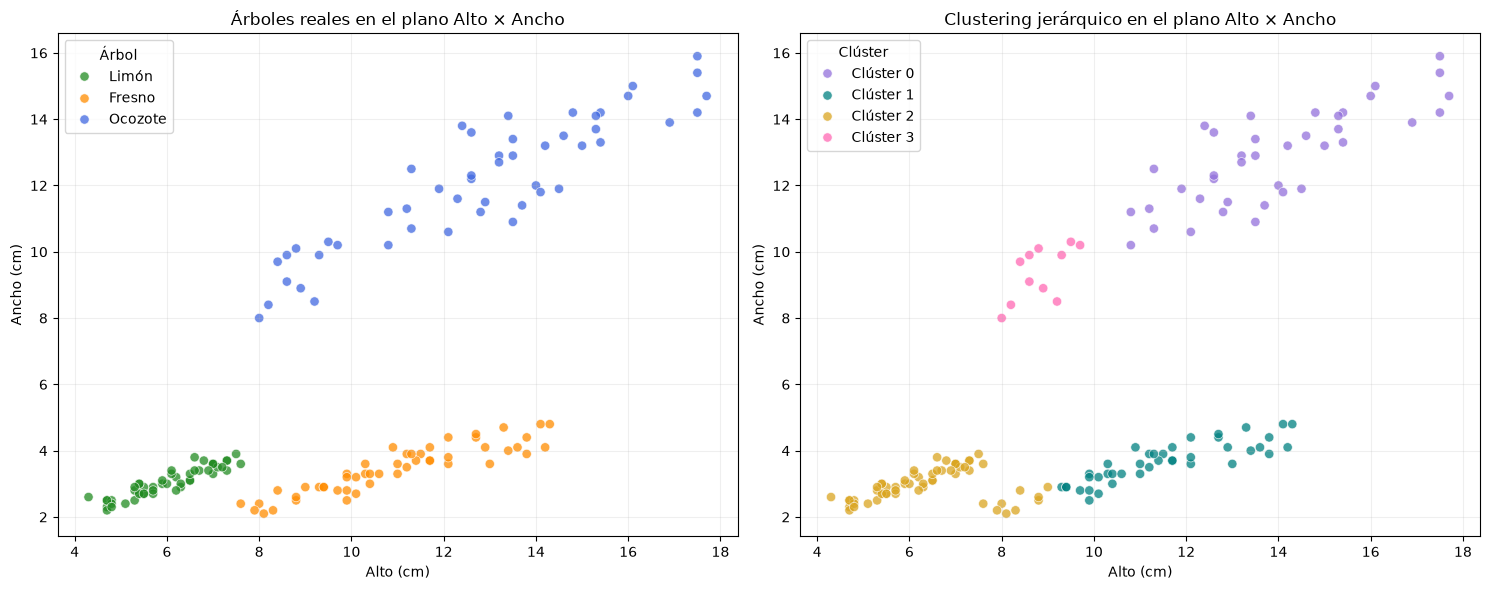

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Clases reales
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=np.array(CLASES)[y],
    hue_order=CLASES,
    palette=COLORES_CLASE,
    alpha=0.75,
    s=45,
    ax=axes[0]
)

axes[0].set_title("Árboles reales en el plano Alto × Ancho")
axes[0].set_xlabel("Alto (cm)")
axes[0].set_ylabel("Ancho (cm)")
axes[0].legend(title="Árbol")
axes[0].grid(alpha=0.2)

# Clústeres obtenidos
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_jerarquico,
    hue_order=orden_cluster_jerarquico,
    palette=paleta_cluster_jerarquico,
    alpha=0.75,
    s=45,
    ax=axes[1]
)

axes[1].set_title("Clustering jerárquico en el plano Alto × Ancho")
axes[1].set_xlabel("Alto (cm)")
axes[1].set_ylabel("Ancho (cm)")
axes[1].legend(title="Clúster")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Comparación visual con las etiquetas reales

Al comparar ambas gráficas se observa que los clústeres siguen de cerca a los árboles reales. Las diferencias aparecen en dos zonas:

1. **Hojas de Ocozote más pequeñas:** las hojas de Ocozote con alto menor a 10 cm forman un grupo propio (clúster 3), separado del resto de su clase por un hueco en el alto. El clustering no puede saber que ambos grupos pertenecen al mismo árbol; solamente detecta que forman dos regiones compactas.
2. **Frontera entre Limón y Fresno:** las 9 hojas de Fresno asignadas al clúster 2 son las más cortas de su clase y se encuentran junto a las hojas de Limón, en la zona donde ambas clases casi se tocan en el alto. Como también tienen anchos similares, el modelo no tiene información suficiente para separarlas.

El clustering se ajustó en el espacio de las dos características originales estandarizadas, y las gráficas se muestran en ese mismo espacio expresado en centímetros, sin PCA.

---

# Modelo 2: Clustering K-means

En esta sección se aplicará el algoritmo **K-means** al corpus de hojas.

El modelo se ajustará utilizando las **2 características estandarizadas** (las mismas variables `X_scaled` del clustering jerárquico). Se probarán diferentes números de clústeres, dos métodos de inicialización y distintos números de reinicios, y se calculará el **coeficiente de silueta** para seleccionar la configuración final.

Las etiquetas reales de los árboles no se utilizarán durante el entrenamiento; solamente se emplearán posteriormente para comparar y evaluar los agrupamientos obtenidos.

---

In [24]:
from sklearn.cluster import KMeans

resultados_kmeans = []

for inicializacion in ["k-means++", "random"]:
    for reinicios in [1, 10, 20]:
        for n_clusters in range(2, 7):

            modelo_kmeans = KMeans(
                n_clusters=n_clusters,
                init=inicializacion,
                n_init=reinicios,
                random_state=42
            )

            etiquetas_kmeans = modelo_kmeans.fit_predict(X_scaled)

            silueta = silhouette_score(
                X_scaled,
                etiquetas_kmeans
            )

            valores, cantidades = np.unique(
                etiquetas_kmeans,
                return_counts=True
            )

            resultados_kmeans.append({
                "init": inicializacion,
                "n_init": reinicios,
                "n_clusters": n_clusters,
                "silueta": silueta,
                "inercia": modelo_kmeans.inertia_,
                "distribucion": sorted(cantidades.tolist(), reverse=True)
            })

resultados_kmeans_df = pd.DataFrame(resultados_kmeans)

print("Configuraciones evaluadas:", len(resultados_kmeans_df))

# Resumen por número de clústeres con la inicialización k-means++ y 20 reinicios
resultados_kmeans_df[
    (resultados_kmeans_df["init"] == "k-means++")
    & (resultados_kmeans_df["n_init"] == 20)
].reset_index(drop=True)

Configuraciones evaluadas: 30


,init,n_init,n_clusters,silueta,inercia,distribucion
0,k-means++,20,2,0.595809,104.894367,"[108, 42]"
1,k-means++,20,3,0.570948,52.375853,"[58, 53, 39]"
2,k-means++,20,4,0.610609,29.344702,"[58, 42, 32, 18]"
3,k-means++,20,5,0.611521,21.553204,"[58, 42, 23, 14, 13]"
4,k-means++,20,6,0.563927,14.251385,"[51, 26, 23, 23, 14, 13]"


In [25]:
# Efecto de la inicialización y los reinicios sobre la silueta y la inercia
tabla_inicializacion = resultados_kmeans_df.pivot_table(
    index="n_clusters",
    columns=["init", "n_init"],
    values=["silueta", "inercia"]
).round(4)

tabla_inicializacion

inercia                                                    \
init       k-means++                        random                       
n_init            1         10        20        1         10        20   
n_clusters                                                               
2           104.8944  104.8944  104.8944  104.8944  104.8944  104.8944   
3            52.3759   52.3759   52.3759   52.3759   52.3759   52.3759   
4            29.3880   29.3447   29.3447   29.3880   29.3447   29.3447   
5            22.0862   21.5548   21.5532   22.0862   21.5532   21.5532   
6            14.2514   14.2514   14.2514   18.6437   14.2514   14.2514   

             silueta                                          
init       k-means++                  random                  
n_init            1       10      20      1       10      20  
n_clusters                                                    
2             0.5958  0.5958  0.5958  0.5958  0.5958  0.5958  
3             0.5709  0.5709  0.5709  0.5709  0.5709  0.5709  
4             0.6072  0.6106  0.6106  0.6072  0.6106  0.6106  
5             0.5588  0.6131  0.6115  0.5588  0.6115  0.6115  
6             0.5639  0.5639  0.5639  0.5190  0.5639  0.5639

## Evaluación del número de clústeres

Para seleccionar el número de clústeres se comparan dos criterios:

- **Método del codo:** analiza la reducción de la inercia.
- **Coeficiente de silueta:** mide qué tan compactos y separados están los grupos. Un valor mayor representa una mejor agrupación.

Las curvas corresponden a la inicialización k-means++ con 20 reinicios.

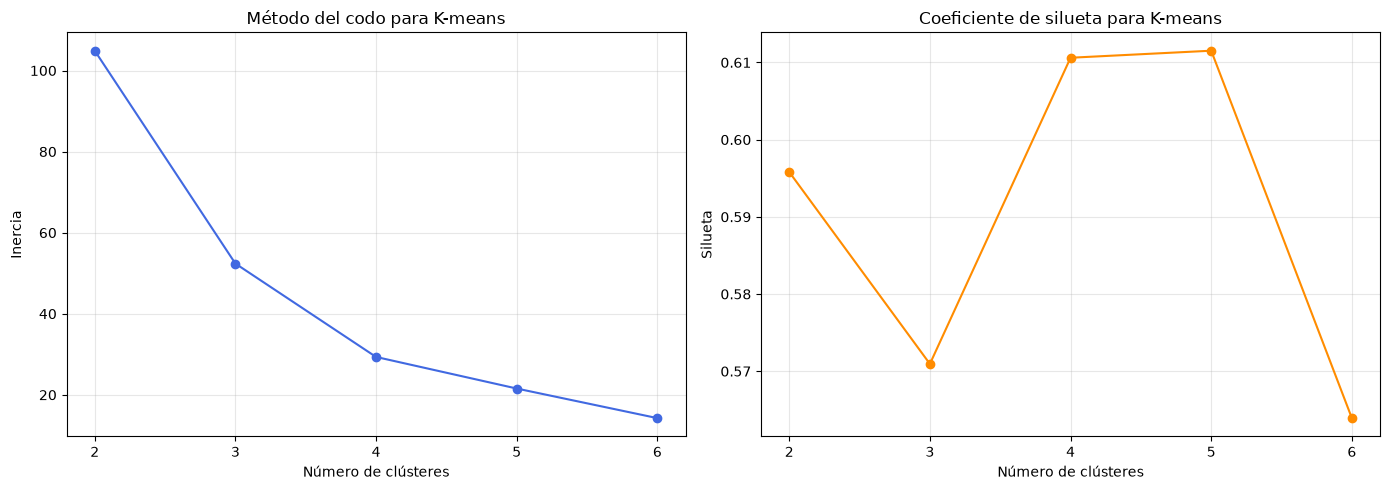

Reducción relativa de la inercia al agregar un clúster (%): [50.07, 43.97, 26.55, 33.88]


In [26]:
curvas_kmeans = resultados_kmeans_df[
    (resultados_kmeans_df["init"] == "k-means++")
    & (resultados_kmeans_df["n_init"] == 20)
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Método del codo
axes[0].plot(
    curvas_kmeans["n_clusters"],
    curvas_kmeans["inercia"],
    marker="o",
    color="royalblue"
)

axes[0].set_title("Método del codo para K-means")
axes[0].set_xlabel("Número de clústeres")
axes[0].set_ylabel("Inercia")
axes[0].set_xticks(curvas_kmeans["n_clusters"])
axes[0].grid(alpha=0.3)

# Coeficiente de silueta
axes[1].plot(
    curvas_kmeans["n_clusters"],
    curvas_kmeans["silueta"],
    marker="o",
    color="darkorange"
)

axes[1].set_title("Coeficiente de silueta para K-means")
axes[1].set_xlabel("Número de clústeres")
axes[1].set_ylabel("Silueta")
axes[1].set_xticks(curvas_kmeans["n_clusters"])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Reducción relativa de la inercia al agregar un clúster (%):",
    (-curvas_kmeans["inercia"].pct_change() * 100).round(2).tolist()[1:]
)

In [27]:
# Paso 1: para cada k se conserva la solución con menor inercia (objetivo de K-means).
# La inicialización y los reinicios sirven para alcanzar ese mínimo; en caso de empate
# se prefiere k-means++ y el mayor número de reinicios.
tamano_minimo = int(np.ceil(0.05 * len(X_scaled)))

candidatas_kmeans = resultados_kmeans_df[
    resultados_kmeans_df["distribucion"].apply(min) >= tamano_minimo
].copy()

candidatas_kmeans["inercia_redondeada"] = candidatas_kmeans["inercia"].round(4)
candidatas_kmeans["es_kmeanspp"] = candidatas_kmeans["init"] == "k-means++"

mejor_por_k_kmeans = (
    candidatas_kmeans
    .sort_values(
        by=["n_clusters", "inercia_redondeada", "es_kmeanspp", "n_init"],
        ascending=[True, True, False, False]
    )
    .groupby("n_clusters")
    .head(1)
    .reset_index(drop=True)
)

# Paso 2: entre esas soluciones se elige el número de clústeres con mayor silueta
mejor_config_kmeans = mejor_por_k_kmeans.loc[
    mejor_por_k_kmeans["silueta"].idxmax()
]

print("Configuraciones descartadas por clústeres pequeños:",
      len(resultados_kmeans_df) - len(candidatas_kmeans))
display(mejor_por_k_kmeans[["init", "n_init", "n_clusters", "silueta", "inercia", "distribucion"]])

print("Configuración seleccionada:")
print(mejor_config_kmeans[["init", "n_init", "n_clusters", "silueta", "inercia", "distribucion"]])

Configuraciones descartadas por clústeres pequeños: 0


,init,n_init,n_clusters,silueta,inercia,distribucion
0,k-means++,20,2,0.595809,104.894367,"[108, 42]"
1,k-means++,20,3,0.570948,52.375853,"[58, 53, 39]"
2,k-means++,20,4,0.610609,29.344702,"[58, 42, 32, 18]"
3,k-means++,20,5,0.611521,21.553204,"[58, 42, 23, 14, 13]"
4,k-means++,20,6,0.563927,14.251385,"[51, 26, 23, 23, 14, 13]"


Configuración seleccionada:
init                       k-means++
n_init                            20
n_clusters                         5
silueta                     0.611521
inercia                    21.553204
distribucion    [58, 42, 23, 14, 13]
Name: 3, dtype: object


In [28]:
# Composición de K-means con 2 y 3 clústeres (solo para interpretar)
for n_clusters in [2, 3]:
    etiquetas_k = KMeans(
        n_clusters=n_clusters,
        init="k-means++",
        n_init=20,
        random_state=42
    ).fit_predict(X_scaled)

    print(f"K-means con k = {n_clusters}:")
    display(pd.crosstab(
        etiquetas_k,
        np.array(CLASES)[y],
        rownames=["Cluster"],
        colnames=["Árbol real"]
    )[CLASES])

K-means con k = 2:


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,0,42
1,50,50,8


K-means con k = 3:


Árbol real,Limón,Fresno,Ocozote
Cluster,,,
0,0,0,39
1,50,8,0
2,0,42,11


## Selección de la configuración final

Se evaluaron 30 configuraciones, resultado de combinar 2 métodos de inicialización (k-means++ y aleatoria), 3 números de reinicios (1, 10 y 20) y de 2 a 6 clústeres. Ninguna configuración formó clústeres con menos de 8 hojas.

La inicialización y los reinicios no modifican el resultado con 2 y 3 clústeres. Con 4 o más clústeres, un solo reinicio puede quedar en un mínimo local con mayor inercia: por ejemplo, con 5 clústeres la inercia fue de 22.0862 con un reinicio y de 21.5532 con 20 reinicios. Por ello, para cada número de clústeres se conservó la solución con menor inercia, que es el objetivo que K-means busca minimizar, y entre esas soluciones se eligió el número de clústeres con mayor silueta. No se eligieron los reinicios directamente por silueta, porque eso puede favorecer una solución que K-means no alcanzó correctamente.

El método del codo no presenta un punto de quiebre definido. La inercia se reduce 50.07 % al pasar de 2 a 3 clústeres y 43.97 % al pasar de 3 a 4. Después la reducción es menor (26.55 % de 4 a 5 y 33.88 % de 5 a 6).

El coeficiente de silueta alcanza su valor máximo con **5 clústeres**, con un resultado de **0.6115**, prácticamente igual al obtenido con 4 clústeres (0.6106). Con 3 clústeres la silueta baja a 0.5709, por debajo también de 2 clústeres (0.5958). Al igual que en el clustering jerárquico, la silueta no favorece 3 clústeres:

- Con **k = 2**, K-means separa 42 hojas de Ocozote y agrupa las demás (50 de Limón, 50 de Fresno y 8 de Ocozote).
- Con **k = 3**, un grupo contiene 39 hojas de Ocozote, otro las 50 de Limón con 8 de Fresno, y el tercero 42 de Fresno con 11 de Ocozote.

Se seleccionó la configuración final de **K-means con 5 clústeres, inicialización k-means++ y 20 reinicios**, que produjo grupos de **58, 42, 23, 14 y 13 hojas**. La selección se realizó utilizando únicamente las características estandarizadas y métricas internas del agrupamiento, sin utilizar los árboles reales.

In [29]:
mejor_modelo_kmeans = KMeans(
    n_clusters=int(mejor_config_kmeans["n_clusters"]),
    init=mejor_config_kmeans["init"],
    n_init=int(mejor_config_kmeans["n_init"]),
    random_state=42
)

clusters_kmeans = mejor_modelo_kmeans.fit_predict(X_scaled)
k_kmeans = mejor_modelo_kmeans.n_clusters

valores_kmeans, cantidades_kmeans = np.unique(
    clusters_kmeans,
    return_counts=True
)

silueta_kmeans = silhouette_score(
    X_scaled,
    clusters_kmeans
)

print("Clústeres:", valores_kmeans)
print("Cantidad de hojas por clúster:", cantidades_kmeans)
print("Coeficiente de silueta:", silueta_kmeans)
print("Inercia:", mejor_modelo_kmeans.inertia_)

Clústeres: [0 1 2 3 4]
Cantidad de hojas por clúster: [58 23 42 13 14]
Coeficiente de silueta: 0.6115213928894707
Inercia: 21.553203920359458


## Visualización de K-means en el plano Alto × Ancho

El modelo K-means fue ajustado utilizando las 2 características estandarizadas. Para representar los resultados, las hojas y los centroides se grafican en el **espacio original, en centímetros**; los centroides se regresan a centímetros invirtiendo la estandarización. No se utiliza PCA.

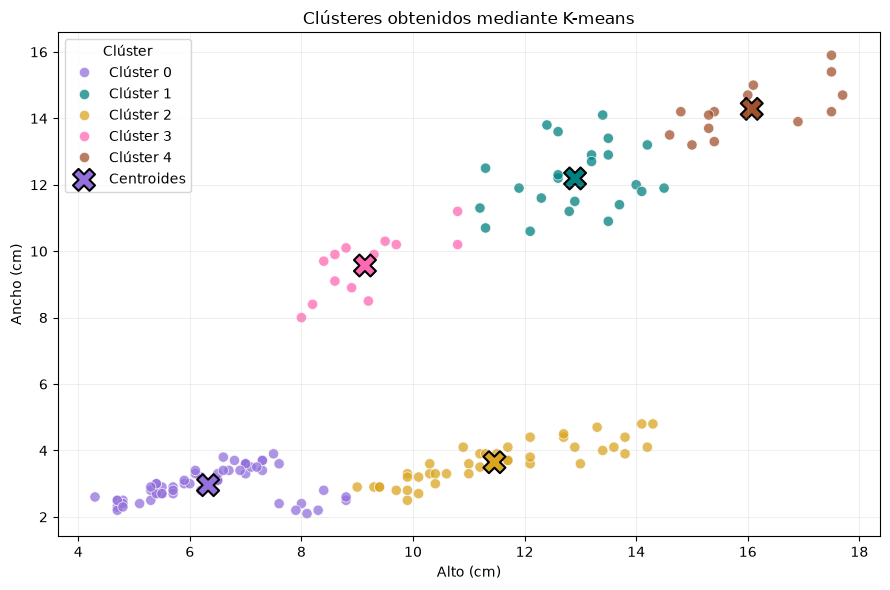

,Alto (cm),Ancho (cm)
Clúster 0,6.33,2.96
Clúster 1,12.90,12.19
Clúster 2,11.46,3.65
Clúster 3,9.14,9.57
Clúster 4,16.07,14.29


In [30]:
# Centroides regresados a centímetros
centroides_kmeans_cm = scaler.inverse_transform(
    mejor_modelo_kmeans.cluster_centers_
)

nombres_cluster_kmeans = np.array(
    [f"Clúster {c}" for c in clusters_kmeans]
)

orden_cluster_kmeans = [f"Clúster {c}" for c in range(k_kmeans)]

paleta_cluster_kmeans = dict(
    zip(orden_cluster_kmeans, COLORES_CLUSTER)
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_kmeans,
    hue_order=orden_cluster_kmeans,
    palette=paleta_cluster_kmeans,
    alpha=0.75,
    s=55
)

# Dibujar los centroides
plt.scatter(
    centroides_kmeans_cm[:, 0],
    centroides_kmeans_cm[:, 1],
    marker="X",
    s=250,
    c=COLORES_CLUSTER[:k_kmeans],
    edgecolor="black",
    linewidth=1.5,
    label="Centroides"
)

plt.title("Clústeres obtenidos mediante K-means")
plt.xlabel("Alto (cm)")
plt.ylabel("Ancho (cm)")
plt.legend(title="Clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

pd.DataFrame(
    centroides_kmeans_cm,
    columns=caracteristicas,
    index=orden_cluster_kmeans
).round(2)

### Interpretación de la visualización

La gráfica muestra los cinco clústeres sobre el alto y el ancho en centímetros. Las marcas en forma de X representan los centroides calculados por K-means, regresados a centímetros.

Dos clústeres ocupan la región de hojas angostas:

- **Clúster 0**, con centroide en 6.33 cm de alto y 2.96 cm de ancho (las hojas más pequeñas).
- **Clúster 2**, con centroide en 11.46 cm de alto y 3.65 cm de ancho (hojas alargadas).

Los otros tres clústeres dividen la región de hojas anchas a lo largo de la diagonal:

- **Clúster 3**, con centroide en 9.14 × 9.57 cm.
- **Clúster 1**, con centroide en 12.90 × 12.19 cm.
- **Clúster 4**, con centroide en 16.07 × 14.29 cm.

K-means asigna cada hoja al centroide más cercano, por lo que tiende a formar grupos compactos y de tamaño similar. La región de hojas anchas es la más dispersa del corpus y está alargada en diagonal, porque el alto y el ancho crecen juntos. Por eso K-means la corta en tres segmentos en lugar de tratarla como un solo grupo.

In [31]:
arboles_reales = pd.Series(
    np.array(CLASES)[y],
    name="Árbol real"
)

clusters_kmeans_serie = pd.Series(
    clusters_kmeans,
    name="Clúster"
)

tabla_comparacion_kmeans = pd.crosstab(
    clusters_kmeans_serie,
    arboles_reales
)[CLASES]

ari_kmeans = adjusted_rand_score(
    y,
    clusters_kmeans
)

nmi_kmeans = normalized_mutual_info_score(
    y,
    clusters_kmeans
)

print("Comparación entre clústeres y árboles reales:")
display(tabla_comparacion_kmeans)

print("Índice Rand ajustado:", ari_kmeans)
print("Información mutua normalizada:", nmi_kmeans)

Comparación entre clústeres y árboles reales:


Árbol real,Limón,Fresno,Ocozote
Clúster,,,
0,50,8,0
1,0,0,23
2,0,42,0
3,0,0,13
4,0,0,14


Índice Rand ajustado: 0.671149601827592
Información mutua normalizada: 0.7419442749299275


## Evaluación frente a las etiquetas reales

Cuatro de los cinco clústeres contienen hojas de un solo árbol: el clúster 2 agrupó 42 hojas de Fresno, y los clústeres 1, 3 y 4 agruparon 23, 13 y 14 hojas de Ocozote, respectivamente. El único clúster mixto es el 0, que reunió las 50 hojas de Limón y 8 hojas de Fresno.

El índice Rand ajustado fue de 0.6711 y la información mutua normalizada fue de 0.7419. Estos resultados indican una correspondencia considerable entre los grupos encontrados por K-means y los árboles reales, aunque Ocozote quedó repartido en tres clústeres, lo cual reduce ambos índices.

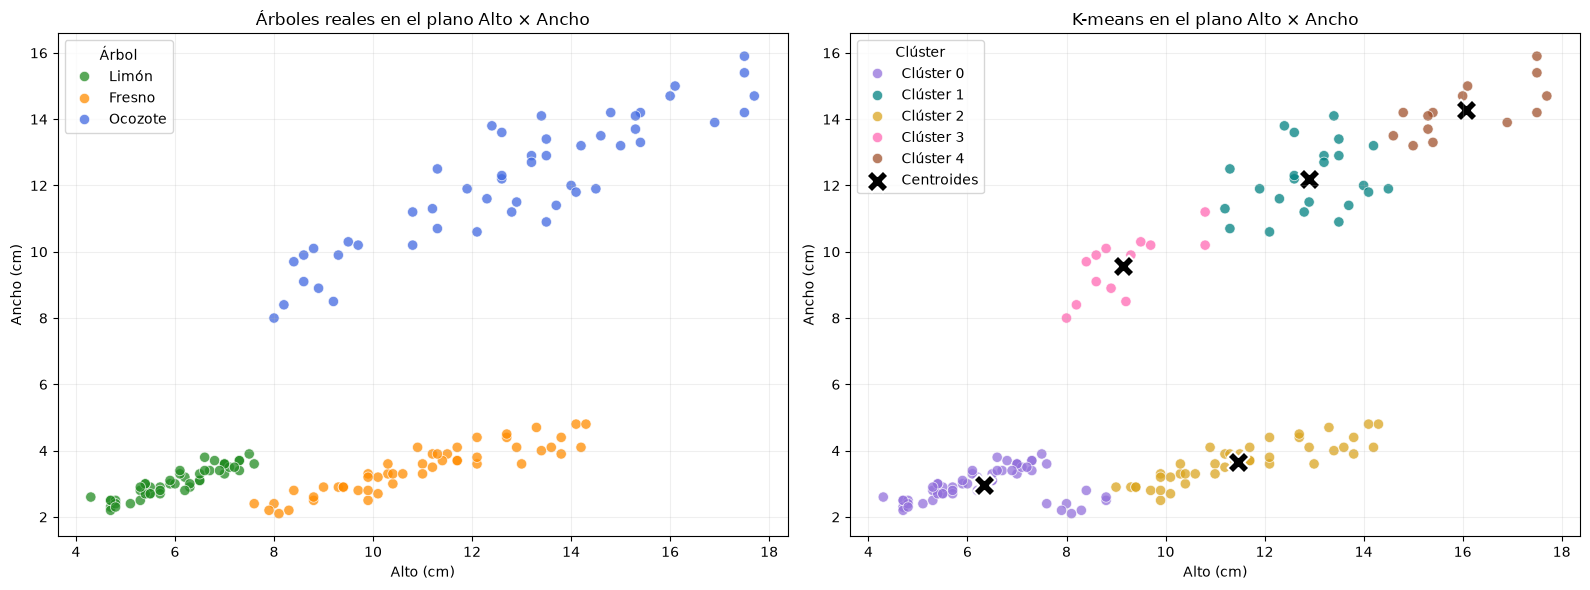

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Árboles reales
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=arboles_reales,
    hue_order=CLASES,
    palette=COLORES_CLASE,
    alpha=0.75,
    s=55,
    ax=axes[0]
)

axes[0].set_title("Árboles reales en el plano Alto × Ancho")
axes[0].set_xlabel("Alto (cm)")
axes[0].set_ylabel("Ancho (cm)")
axes[0].legend(title="Árbol")
axes[0].grid(alpha=0.2)

# Clústeres obtenidos con K-means
sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=nombres_cluster_kmeans,
    hue_order=orden_cluster_kmeans,
    palette=paleta_cluster_kmeans,
    alpha=0.75,
    s=55,
    ax=axes[1]
)

axes[1].scatter(
    centroides_kmeans_cm[:, 0],
    centroides_kmeans_cm[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroides"
)

axes[1].set_title("K-means en el plano Alto × Ancho")
axes[1].set_xlabel("Alto (cm)")
axes[1].set_ylabel("Ancho (cm)")
axes[1].legend(title="Clúster")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Comparación visual con las etiquetas reales

Al comparar ambas gráficas se observa una correspondencia clara entre los grupos obtenidos mediante K-means y los árboles reales. La separación entre hojas anchas y angostas coincide exactamente con la separación entre Ocozote y las otras dos clases.

Las diferencias aparecen en dos zonas:

1. **Ocozote:** sus hojas se reparten en tres clústeres a lo largo de la diagonal. No se trata de un error de asignación entre clases, sino de una división de una misma clase en grupos de distinto tamaño de hoja.
2. **Frontera entre Limón y Fresno:** 8 hojas de Fresno quedaron en el clúster de Limón. Son hojas de Fresno cortas que se encuentran cerca de las de Limón, en la zona donde ambas clases casi se tocan en el alto y tienen anchos similares.

El clustering se ajustó en el espacio de las dos características originales estandarizadas y se graficó en ese mismo espacio expresado en centímetros, sin PCA.